# Essex County Prosecution Analysis

**Source:** Essex DA extract: `01 Criminal Charges Filed`, `02 Criminal Charges Disposed`, `03 Bail and Pretrial Detention` (2017-01-01 to 2025-12-31)
**Study period:** 2017 to 2024 (filing year)

**Agreed criteria (all counties)**
- **Unit:** one row = one case = one docket number per defendant. Dockets with multiple defendants are split into one case per defendant.
- **Offense classification:** each case is classified by its most serious charge. Essex has no felony / misdemeanor field, so the offense severity order is used, then charge number.
- **Outcome:** each case gets its most severe outcome across all charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal > Other > Unknown). Open cases are excluded from outcome metrics.
- **Missing data:** the coverage table comes first. Fields over 20% missing are marked "insufficient data" and their metrics are not reported. "Unknown" is kept as its own category.

## Setup

In [1]:
import sys, subprocess, os
repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from viz_style import (set_style, stacked_pct_bar, save_fig, normalize_outcome,
                       case_outcome, OUTCOME_COLORS, TEXT_SECONDARY)
import county_charts as cc

set_style()

COUNTY = "essex"
YEARS = range(2017, 2025)     # 2017 to 2024
MISSING_THRESHOLD = 0.20      # fields above this are "insufficient data"
MIN_CELL = 30                 # suppress disparity cells smaller than this

FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

## Load Data
Paths point at the CSV exports in the county folder. `read_any` saves a fast `.pkl` copy next to each file on the first run, so later runs load in seconds.

In [2]:
FILED_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/01 Criminal Charges Filed 2017-01-01_2025-12-31.csv"       # all filed charges (includes open cases)
DISPOSED_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/02 Criminal Charges Disposed 2017-01-01_2025-12-31.csv"  # disposed charges
# (.xlsx versions work too: read_any picks the reader from the extension)

def read_any(path):
    """Read a file once, then reuse a fast pickle copy saved next to it.
    Handles parquet, Excel, and CSVs saved by Excel with ';' separators."""
    cache = Path(path).with_suffix(".pkl")
    if cache.exists():
        return pd.read_pickle(cache)
    if path.endswith(".parquet"):
        df = pd.read_parquet(path)
    elif path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, dtype=str)
    else:
        for enc in ("utf-8-sig", "cp1252"):
            try:
                with open(path, encoding=enc) as f:
                    header = f.readline()
                sep = ";" if header.count(";") > header.count(",") else ","
                df = pd.read_csv(path, sep=sep, low_memory=False, dtype=str, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
    df.columns = df.columns.str.replace("\ufeff", "").str.replace("ï»¿", "").str.strip()
    df.to_pickle(cache)
    return df

def parse_dates(s):
    """Dates arrive as '2017-01-03 00:00:00' (Excel) or '3.01.2017' (CSV saved by Excel).
    Impossible years (e.g. 3022) become missing."""
    s = s.fillna("").astype(str).str.strip().replace({"": None, "nan": None, "NaT": None, "None": None})
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%d.%m.%Y", "%d.%m.%Y %H:%M", "%m/%d/%Y", "%m/%d/%Y %H:%M"]:
        miss = out.isna() & s.notna()
        if not miss.any():
            break
        p = pd.to_datetime(s[miss], format=fmt, errors="coerce")
        out[miss] = p.where(p.dt.year.between(1990, 2026)).astype("datetime64[ns]")
    return out

def label(s, names):
    """Map raw codes to readable labels: blank -> Unknown, unlisted code -> Other."""
    s = s.fillna("").astype(str).str.strip().replace({"nan": "", "None": "", "Unknown": "", "Missing": ""})
    return s.map(names).where(s != "", "Unknown").fillna("Other")

def add_sentence(raw):
    """Essex has no sentence-type column. Build one from the jail-time fields:
    actual (committed) jail time -> COMMITTED; suspended jail or a probation disposition -> PROBATION;
    fine / filed dispositions -> FINE-FILED; jail imposed with nothing suspended -> COMMITTED (provisional)."""
    num = lambda c: pd.to_numeric(raw[c], errors="coerce").fillna(0) > 0
    actual, imposed, suspended = num("Nmbr Day Actl Jl Impsd"), num("Nmbr Day Jl Impsd"), num("Nmbr Day Jl Spnd Impsd")
    code = raw["Code Dspstn"].astype(str).str.strip()
    s = pd.Series(np.nan, index=raw.index, dtype=object)
    s[code.isin(["GFN", "GFL", "DFL"])] = "FINE-FILED"
    s[imposed & ~suspended & ~code.isin(["GPROB", "DPO"])] = "COMMITTED"
    s[suspended | code.isin(["GPROB", "DPO"])] = "PROBATION"
    s[actual | code.eq("DYS")] = "COMMITTED"
    raw["Sentence (derived)"] = s
    return raw

# Shared name : your column name. Set to None if your county doesn't have it.
COLS = {
    "docket_number":    "Id Cs",
    "defendant_id":     "Id Prsn Mstr",           # person ID: links the same defendant across cases
    "charge_count":     "Id Dfndnt Chrg",         # charge ID (order of charges)
    "filing_date":      "Date Evnt",              # arraignment event date (ARR / 58A / YO)
    "disposition_date": "Date Dspstn",
    "disposition":      "Code Dspstn",            # detailed disposition, mapped to buckets below
    "charge_level":     None,                     # no felony / misdemeanor field
    "offense_category": None,                     # built from the charge description (next section)
    "court":            "Desc Crt Lctn (ACTION EVENT)",
    "race":             "Code Rc",
    "sex":              "Code Sex",
    "sentence_type":    "Sentence (derived)",     # built from the jail-time fields (add_sentence)
}
RACE_NAMES = {"W": "White", "B": "Black", "H": "Hispanic", "A": "Asian",
              "M": "Other", "N": "Other", "P": "Other", "PI": "Other",
              "U": "Unknown", "0": "Unknown"}
SEX_NAMES = {"M": "Male", "F": "Female", "U": "Unknown", "0": "Unknown"}
DESC_COL, CODE_COL = "Desc Chrg", "Code Chrg"   # used for offense categories

def standardize(raw):
    rename = {v: k for k, v in COLS.items() if v is not None and v in raw.columns}
    out = raw.rename(columns=rename)
    for k in COLS:
        if k not in out.columns:
            out[k] = np.nan
    out["case_key"] = out["docket_number"].fillna("").astype(str).str.strip() + "_" + out["defendant_id"].fillna("").astype(str).str.strip()
    out["filing_date"] = parse_dates(out["filing_date"])
    out["disposition_date"] = parse_dates(out["disposition_date"])
    out["filing_year"] = out["filing_date"].dt.year
    out["disposition"] = out["disposition"].fillna("").astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
    for f in ("race", "sex"):
        out[f + "_blank"] = out[f].fillna("").astype(str).str.strip().isin(["", "nan", "None"])
    out["race"] = label(out["race"], RACE_NAMES)
    out["sex"] = label(out["sex"], SEX_NAMES)
    return out

raw_filed = read_any(FILED_PATH)
raw_disposed = add_sentence(read_any(DISPOSED_PATH))
filed = standardize(raw_filed)
disposed = standardize(raw_disposed)

missing_cols = [k for k, v in COLS.items() if v is None or v not in raw_disposed.columns]
print("Not found in extract:", missing_cols)
print(f"Filed: {len(filed):,} charges, {filed['case_key'].nunique():,} cases")
print(f"Disposed: {len(disposed):,} charges, {disposed['case_key'].nunique():,} cases")

Not found in extract: ['charge_level', 'offense_category']
Filed: 450,955 charges, 151,132 cases
Disposed: 436,315 charges, 149,007 cases


## Offense Categories
The extract has no offense category that matches the shared categories, so each charge is classified from its **charge description** (falling back to the law chapter in the charge code). Categories match the other counties' figures. A case takes the category of its most serious charge (see Build Case Table).

In [3]:
OFFENSE_RULES = [  # first match wins
    ("Sexual Offenses",         r"RAPE|INDECENT|SEXUAL|\bLEWD|OPEN (AND|&) GROSS|ENTICE|CHILD PORN|SEX OFFENDER|ACCOST|PROSTITUT|OBSCENE"),
    ("Robbery",                 r"ROBBERY|CARJACK"),
    ("Domestic Violence",       r"FAMILY|HOUSEHOLD|209A|ABUSE PREVENTION|STRANGUL|SUFFOCAT|13M"),
    ("Assault w/ Weapon",       r"(A&B|ASSAULT|ASLT|ATTEMPT).*(DANGEROUS WEAPON|D/W|\bDW\b)|DANGEROUS WEAPON.*(A&B|ASSAULT)"),
    ("Firearms/Weapons",        r"FIREARM|WEAPON|AMMUNITION|\bGUN\b|FID CARD|SHOTGUN|RIFLE|KNIFE|DIRK|FEEDING DEVICE"),
    ("Drug Distribution",       r"DISTRIB|TRAFFIC|MANUFACTUR|INTENT TO DIST|DRUG.*SCHOOL|SCHOOL.*DRUG|GRAMS"),
    ("Drug Possession",         r"DRUG|CLASS [A-E]\b|MARIJUANA|HEROIN|HERION|COCAINE|NARCOTIC|SUBSTANCE|HYPODERMIC"),
    ("OUI/DUI",                 r"\bOUI|UNDER THE INFLUENCE|\bDUI\b|OPERATING UNDER"),
    ("Motor Vehicle",           r"LEAVE SCENE|LICENSE SUSP|LICENSE REVOK|UNLICENSED|UNINSURED|UNREGISTERED|REGISTRATION|"
                                r"NEGLIGENT OPERATION|RECKLESS OPERATION|MARKED LANES|SPEEDING|INSPECTION|STICKER|"
                                r"STOP SIGN|RED LIGHT|SEAT BELT|PLATE|USE WITHOUT AUTHORITY|OPERATE.*MV|OP MV|\bMV\b|"
                                r"MOTOR VEHICLE|ATTACHING|FAIL TO STOP|YIELD|LANE|HEADLIGHT|TAILLIGHT"),
    ("Breaking & Entering",     r"B&E|BREAKING|BREAK AND|BREAK &|BURGLAR|\bB & E\b|BREAK/ENTER|ENTER W/O BREAK|HOME INVASION"),
    ("Assault & Battery",       r"A&B|ASSAULT|BATTERY|MAYHEM|ASLT"),
    ("Fraud/Forgery",           r"FRAUD|FORG|UTTER|COUNTERFEIT|IDENTITY|FICTITIOUS|BAD CHECK|CREDIT CARD|FALSE (STATEMENT|PRETENSE|CLAIM|ENTRY)"),
    ("Larceny/Theft",           r"LARCENY|SHOPLIFT|THEFT|STOLEN|STEAL|EMBEZZL|RECEIV"),
    ("Property Damage",         r"DESTRUCT|DESTROY|VANDAL|MALICIOUS|WANTON|DAMAGE|GRAFFITI|DEFAC|ARSON|BURN|TAG PROPERTY"),
    ("Disorderly/Public Order", r"DISORDERLY|DISTURB|RESIST|TRESPASS|THREAT|INTIMIDAT|CONTEMPT|FALSE NAME|LOITER|"
                                r"DRUNK|ALCOHOL|LIQUOR|INTOX|NUISANCE|ESCAPE|OBSTRUCT|HARASS|WITNESS|ANNOY|RIOT|"
                                r"AFFRAY|FALSE (REPORT|ALARM)|POLICE OFFICER|PUBLIC|DISSEMINAT|CRUELTY|CONSPIRACY"),
]
_RULES = [(c, re.compile(p)) for c, p in OFFENSE_RULES]
_CHAPTER = re.compile(r"^\s*(?:C\.?\s*)?(\d+[A-Z]?)")

def classify_offense(desc, code):
    d = str(desc).upper()
    for cat, rx in _RULES:
        if rx.search(d):
            return cat
    m = _CHAPTER.match(str(code).upper())
    if m and m.group(1) in ("90", "89", "90B", "90C", "720C", "540C"):
        return "Motor Vehicle"
    return "Other/Unknown"

def add_offense(df):
    desc = df[DESC_COL].fillna("").astype(str)
    code = df[CODE_COL].fillna("").astype(str)
    lookup = {k: classify_offense(*k) for k in set(zip(desc, code))}
    df["offense_category"] = [lookup[k] for k in zip(desc, code)]

# Most serious first: breaks ties between charges of the same level (stands in for statutory class)
OFFENSE_PRIORITY = ["Sexual Offenses", "Robbery", "Firearms/Weapons", "Assault w/ Weapon", "Domestic Violence",
                    "Drug Distribution", "Breaking & Entering", "Assault & Battery", "OUI/DUI", "Fraud/Forgery",
                    "Larceny/Theft", "Drug Possession", "Property Damage", "Disorderly/Public Order",
                    "Other/Unknown", "Motor Vehicle"]

for df in (filed, disposed):
    add_offense(df)
(disposed["offense_category"].value_counts(normalize=True) * 100).round(1).rename("% of disposed charges").to_frame()

,% of disposed charges
offense_category,
Motor Vehicle,31.7
Domestic Violence,9.4
Disorderly/Public Order,8.6
Firearms/Weapons,6.7
Assault & Battery,6.3
Assault w/ Weapon,5.6
Drug Distribution,5.4
Larceny/Theft,4.4
Sexual Offenses,4.2


## Map Dispositions and Exclusions
Every Essex `Code Dspstn` is mapped onto the shared buckets: **Trial Conviction, Plea, CWOF, Diversion, Acquittal, Dismissal, Other, Unknown**. Nolle prosequi (NOP) counts as Dismissal.
- **Guilty (GLT, GPROB, GFL, GFN) is provisional as Plea:** the code does not say whether the finding came from a plea or a trial. Only GVL (guilty verdict, lesser offense) is clearly a trial conviction, so Trial Conviction is undercounted.
- Admission to sufficient facts (ASF) counts as CWOF; pre-trial probation (PTP, PTP2) as Diversion.
- Excluded: civil infractions (NRS, RFL, RES, RFN), charges closed because the case was indicted (DIND, SIND, IND: the case continues in Superior Court under a new docket), and non-OUI motor-vehicle charges.
- Other (4.6% of cases) is mostly GCN (generally continued).

In [4]:
(disposed.groupby(["disposition", "Desc Dspstn"], dropna=False).size()
         .sort_values(ascending=False).rename("charges").head(70).to_frame())

,,charges
disposition,Desc Dspstn,
DIS,Dismissed,56828
DIND,Dismissed due to Indictment,52602
DWO,Dismissed Lack of Prosecution W/O Pred.,42247
PLG,Pled Guilty to Charge,40389
DCC,Dismissed Court Costs,36628
...,...,...
NPC,No Probable Cause Found,6
PGPB,Pled Guilty to Probation Violation,4
NAET,No Action Ever Taken,3


In [5]:
COUNTY_OUTCOMES = {
    "GVL": "Trial Conviction",                                    # guilty verdict, lesser offense
    # "Guilty" (GLT and its sentence variants) does not say plea or trial. Counted as Plea: PROVISIONAL.
    **{k: "Plea" for k in ["PLG", "PLO", "GLT", "GPROB", "GFL", "GFN", "DEL", "DPO", "DFL", "YO", "DYS"]},
    "CWF": "CWOF", "ASF": "CWOF",
    "PTP": "Diversion", "PTP2": "Diversion", "DIV": "Diversion",
    "NTG": "Acquittal", "NGJ": "Acquittal", "NGI": "Acquittal", "RFNTG": "Acquittal",
    "DIRV": "Acquittal", "NDEL": "Acquittal",
    **{k: "Dismissal" for k in ["DIS", "DWO", "DWP", "DCC", "NOP", "DNV", "DMP", "DLE", "DIP", "DIF",
                                "DNC", "NO BILL", "NPC", "ACS"]},
    # Everything else (GCN general continuance, MALL motion allowed, MIS mistrial, ...) falls into Other.
}

EXCLUDE_DISPOSITIONS = ["NRS", "RFL", "RES", "RFN",      # civil infractions (responsible / not responsible)
                        "DIND", "SIND", "IND"]           # moved to Superior Court under a new indictment
EXCLUDE_OFFENSES = ["Motor Vehicle"]   # team rule: non-OUI motor-vehicle charges are out of scope

disposed["outcome"] = disposed["disposition"].replace(COUNTY_OUTCOMES).map(normalize_outcome)
n_before = len(disposed)
disposed = disposed[~disposed["disposition"].isin(EXCLUDE_DISPOSITIONS)]
n_civil = n_before - len(disposed)
disposed = disposed[~disposed["offense_category"].isin(EXCLUDE_OFFENSES)]
filed = filed[~filed["offense_category"].isin(EXCLUDE_OFFENSES)]

print(f"Excluded: {n_civil:,} civil / indicted charges, then motor-vehicle charges")
print(disposed["outcome"].value_counts(dropna=False))
print(f"Share in Other: {(disposed['outcome'] == 'Other').mean():.1%}")

Excluded: 102,795 civil / indicted charges, then motor-vehicle charges
outcome
Dismissal           111138
Plea                 87537
CWOF                 27394
Other                 8719
Acquittal             6172
Diversion             4726
Trial Conviction       152
Unknown                 24
Name: count, dtype: int64
Share in Other: 3.5%


## 0. Data Coverage
Share missing and years available for each key field. Fields above 20% missing are marked **insufficient data** and the metrics that depend on them are not reported.

In [6]:
COVERAGE_FIELDS = ["docket_number", "defendant_id", "filing_date", "disposition_date",
                   "disposition", "charge_level", "offense_category", "court",
                   "race", "sex", "sentence_type"]

def years_available(d, field):
    yrs = d.loc[d[field].notna(), "filing_year"].dropna()
    return f"{int(yrs.min())}-{int(yrs.max())}" if len(yrs) else "none"

# Coverage is measured on disposed charges filed 2017-2024. Sentence type only applies to
# convictions, so its coverage is measured on convicted charges.
in_years = disposed[disposed["filing_year"].isin(YEARS)]
convicted_rows = in_years[in_years["outcome"].isin(["Trial Conviction", "Plea"])]
def pct_missing(f):
    d = convicted_rows if f == "sentence_type" else in_years
    if f in ("race", "sex"):                 # blank in the raw extract (coded "unknown" is kept as a group)
        return d[f + "_blank"].mean() * 100
    return d[f].isna().mean() * 100

def pct_unknown(f):
    return (in_years[f] == "Unknown").mean() * 100 if f in ("race", "sex") else np.nan

coverage = pd.DataFrame({
    "pct_missing": [pct_missing(f) for f in COVERAGE_FIELDS],
    "pct_blank_or_coded_unknown": [pct_unknown(f) for f in COVERAGE_FIELDS],
    "years_available": [years_available(in_years, f) for f in COVERAGE_FIELDS],
}, index=COVERAGE_FIELDS).round(1)
coverage["status"] = np.where(coverage["pct_missing"] > MISSING_THRESHOLD * 100,
                              "insufficient data", "ok")

INSUFFICIENT = set(coverage.index[coverage["status"] == "insufficient data"])
print("Insufficient:", INSUFFICIENT or "none")
coverage

Insufficient: {'charge_level', 'sentence_type'}


,pct_missing,pct_blank_or_coded_unknown,years_available,status
docket_number,0.0,NaN,2017-2024,ok
defendant_id,0.0,NaN,2017-2024,ok
filing_date,0.0,NaN,2017-2024,ok
disposition_date,0.0,NaN,2017-2024,ok
disposition,0.0,NaN,2017-2024,ok
charge_level,100.0,NaN,none,insufficient data
offense_category,0.0,NaN,2017-2024,ok
court,0.0,NaN,2017-2024,ok
race,16.3,23.7,2017-2024,ok
sex,0.5,0.5,2017-2024,ok


**Notes:** Coverage is measured on disposed charges filed 2017-2024.
- **Charge level** (felony / misdemeanor) is not in the extract.
- **Race** is blank for 16% of charges (under the threshold, so reported), but blank or coded unknown (U, 0) together is about 24%. Read race results with that in mind.
- **Sentence type** is not a field in Essex: it is built from the jail-time columns (see Q4) and is blank for 27% of convicted charges: **insufficient data**, shown for reference.
- **Filing date** is the arraignment event date (`Date Evnt`).
- **Offense category** is built from the charge description, with the law chapter in the charge code as a fallback.

## Build Case Table
One row per case (docket × defendant), restricted to filing years 2017 to 2024.
- **Most serious charge:** felony over misdemeanor, then lowest charge number as a tiebreak. Replace the tiebreak with statutory class if your extract has it.
- **Outcome:** most severe outcome across charges. Cases with any pending charge are marked Pending and excluded from outcome metrics.

In [7]:
LEVEL_RANK = {}  # charge_level values, most serious first; others rank last

def build_cases(d, with_outcome):
    d = d[d["filing_year"].isin(YEARS)].drop_duplicates().copy()
    d["level_rank"] = d["charge_level"].map(LEVEL_RANK).fillna(9)
    d["offense_rank"] = d["offense_category"].map({c: i for i, c in enumerate(OFFENSE_PRIORITY)}).fillna(99)
    d["charge_count_num"] = pd.to_numeric(d["charge_count"], errors="coerce").fillna(999)
    # Most serious charge: keep that whole row (groupby().first() would mix values from different rows)
    lead = (d.sort_values(["case_key", "level_rank", "offense_rank", "charge_count_num"])
              .drop_duplicates("case_key").set_index("case_key"))
    g = d.groupby("case_key")
    out = pd.DataFrame({
        "filing_year": lead["filing_year"],
        "filing_date": g["filing_date"].min(),
        "charge_level": lead["charge_level"].fillna("Unknown"),
        "offense_category": lead["offense_category"].fillna("Unknown"),
        "court": lead["court"].fillna("Unknown"),
        "race": lead["race"].fillna("Unknown"),
        "sex": lead["sex"].fillna("Unknown"),
        "defendant_id": lead["defendant_id"],
        "n_charges": g["charge_count_num"].nunique(),
    })
    if with_outcome:
        out["outcome"] = g["outcome"].agg(case_outcome)
        out["disposition_date"] = g["disposition_date"].max()
    return out.reset_index()

filed_cases = build_cases(filed, with_outcome=False)
all_disposed_cases = build_cases(disposed, with_outcome=True)
n_pending = (all_disposed_cases["outcome"] == "Pending").sum()
cases = all_disposed_cases[all_disposed_cases["outcome"] != "Pending"].copy()

print(f"Filed cases 2017-2024: {len(filed_cases):,}")
print(f"Disposed cases 2017-2024: {len(cases):,} ({n_pending:,} pending excluded)")

Filed cases 2017-2024: 92,010
Disposed cases 2017-2024: 84,949 (0 pending excluded)


## 1. Volume and Trend
**Question:** How many cases were filed each year, and how has that changed since 2017?
**Metric:** case count per year, % change year over year and vs. 2017.

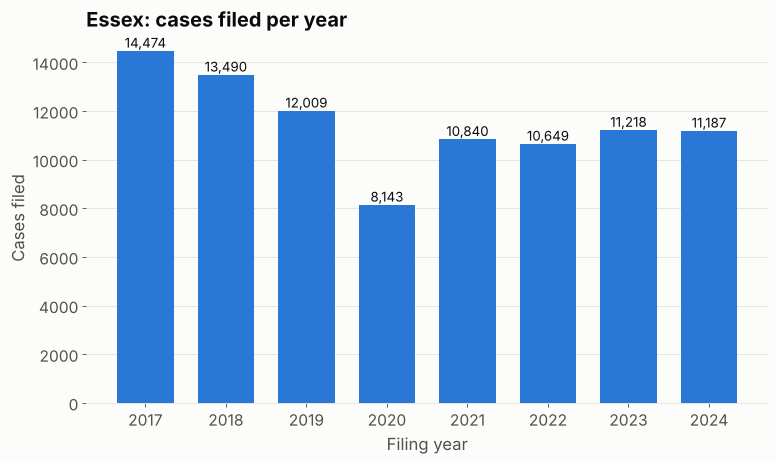

,cases,pct_change_yoy,pct_change_vs_2017
filing_year,,,
2017,14474,NaN,0.0
2018,13490,-6.8,-6.8
2019,12009,-11.0,-17.0
2020,8143,-32.2,-43.7
2021,10840,33.1,-25.1
2022,10649,-1.8,-26.4
2023,11218,5.3,-22.5
2024,11187,-0.3,-22.7


In [8]:
vol = filed_cases.groupby("filing_year").size().rename("cases").to_frame()
vol.index = vol.index.astype(int)
vol["pct_change_yoy"] = (vol["cases"].pct_change() * 100).round(1)
vol["pct_change_vs_2017"] = ((vol["cases"] / vol["cases"].iloc[0] - 1) * 100).round(1)

fig, ax = plt.subplots()
ax.bar(vol.index, vol["cases"], color=OUTCOME_COLORS["Trial Conviction"], width=0.7)
for x, n in zip(vol.index, vol["cases"]):
    ax.text(x, n, f"{n:,}", ha="center", va="bottom", fontsize=12)
ax.set_xticks(list(vol.index))
ax.set_ylabel("Cases filed")
ax.set_xlabel("Filing year")
ax.set_title(f"{COUNTY.title()}: cases filed per year")
save_fig(fig, f"{FIG_DIR}/q1_volume.png")
plt.show()
vol

**How this was calculated**
- **Unit:** cases (docket × defendant)
- **Source:** filed extract, so open cases are counted
- **Date field:** arraignment event date (earliest charge in the case)
- **Filters:** filing years 2017 to 2024; non-OUI motor-vehicle charges excluded
- **Result:** 92,010 cases. Filings fell from 14,474 in 2017 to 11,187 in 2024 (-23%), with the low point in 2020 (8,143).

## 2. Per-Capita Rate
**Question:** How many cases are filed per 10,000 residents?
**Metric:** cases / annual county population × 10,000. Use annual ACS or PEP estimates, not a flat 2020 Census figure.

In [9]:
POPULATION = {  # annual county population estimates (Census PEP or ACS)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}

pop = pd.Series(POPULATION, dtype="float")
if pop.isna().any():
    print("Fill in POPULATION for:", list(pop.index[pop.isna()]))
else:
    per_cap = (vol["cases"] / pop * 10_000).round(1).rename("cases_per_10k").to_frame()
    fig, ax = plt.subplots()
    ax.plot(per_cap.index, per_cap["cases_per_10k"], marker="o", markersize=8,
            linewidth=2, color=OUTCOME_COLORS["Trial Conviction"])
    for x, v in zip(per_cap.index, per_cap["cases_per_10k"]):
        ax.annotate(f"{v:.0f}", (x, v), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=12)
    ax.set_xticks(list(per_cap.index))
    ax.set_ylabel("Cases per 10,000 residents")
    ax.set_xlabel("Filing year")
    ax.set_title(f"{COUNTY.title()}: cases filed per 10,000 residents")
    save_fig(fig, f"{FIG_DIR}/q2_per_capita.png")
    plt.show()
    display(per_cap)

Fill in POPULATION for: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


**How this was calculated**
- **Numerator:** cases filed per year (from Q1)
- **Denominator:** not yet filled in. Add annual Census PEP estimates for Essex County to `POPULATION`.

## 3. Case Outcomes
**Question:** Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?
**Metric:** % of disposed criminal cases by most severe outcome, overall and by year. CWOF is reported separately.

,cases,pct
outcome,,
Dismissal,35516,41.8
Plea,25488,30.0
CWOF,15582,18.3
Other,3933,4.6
Diversion,2618,3.1
Acquittal,1765,2.1
Trial Conviction,39,0.0
Unknown,8,0.0


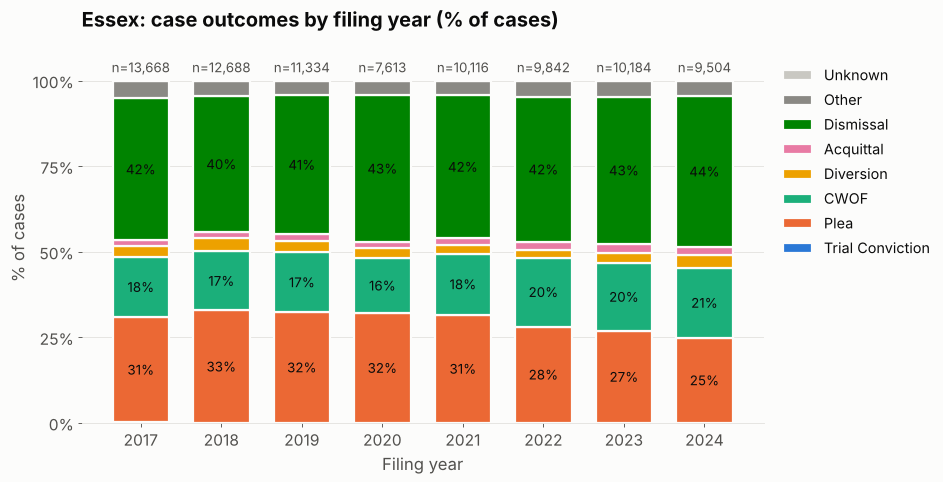

In [10]:
overall = cases["outcome"].value_counts().rename("cases").to_frame()
overall["pct"] = (overall["cases"] / overall["cases"].sum() * 100).round(1)
display(overall)

counts = cases.groupby("filing_year")["outcome"].value_counts().unstack(fill_value=0)
counts.index = counts.index.astype(int)
ax = stacked_pct_bar(counts, unit="cases",
                     title=f"{COUNTY.title()}: case outcomes by filing year (% of cases)",
                     xlabel="Filing year")
save_fig(ax.figure, f"{FIG_DIR}/q3_outcomes_by_year.png")
plt.show()

**How this was calculated**
- **Unit:** disposed criminal cases (docket × defendant), filed 2017-2024
- **Outcome rule:** most severe outcome across the case's charges
- **Date field:** filing year
- **Mapping:** see "Map Dispositions" above (Guilty provisional as Plea)
- **Result:** 84,949 cases: Dismissal 41.8%, Plea 30.0%, CWOF 18.3%, Other 4.6%, Diversion 3.1%, Acquittal 2.1%, Trial Conviction under 0.1% (undercounted: see mapping note).

**Note:** Cases filed in 2023 to 2024 that were still open at extraction are missing from the disposed extract, so recent years lean toward fast-resolving cases.

## 4. Sentencing
**Question:** What share of convictions result in incarceration, probation, or fines/other?
**Metric:** % of convicted cases (Trial Conviction or Plea) by most severe sentence type. The missing share is reported next to every rate.

Sentence type missing for 27.1% of convicted charges (above the 20% threshold): rates are shown with the missing share as 'Unknown'.
Missing sentence type: 15.1% of convicted cases


,cases,pct
sentence,,
Incarceration,11219,43.9
Probation,8318,32.6
Fines/Other,2147,8.4
Unknown,3843,15.1


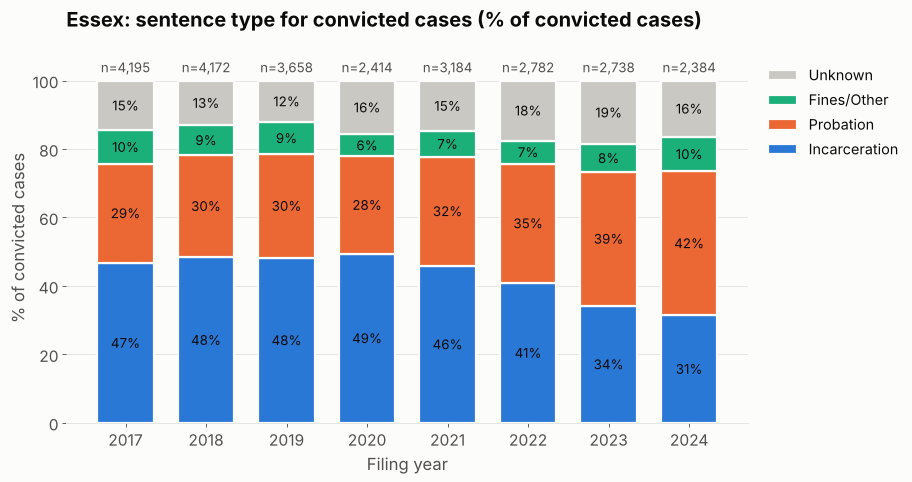

In [11]:
SENTENCE_RANK = ["Incarceration", "Probation", "Fines/Other", "Unknown"]
SENTENCE_COLORS = {"Incarceration": "#2a78d6", "Probation": "#eb6834",
                   "Fines/Other": "#1baf7a", "Unknown": "#c9c8c2"}

def classify_sentence(text):
    """Reads the derived sentence column built in Load Data (add_sentence)."""
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"
    return {"COMMITTED": "Incarceration", "PROBATION": "Probation"}.get(str(text), "Fines/Other")

if "sentence_type" in INSUFFICIENT:
    print(f"Sentence type missing for {coverage.loc['sentence_type', 'pct_missing']}% of convicted charges "
          "(above the 20% threshold): rates are shown with the missing share as 'Unknown'.")
if COLS.get("sentence_type") is None:
    print("Sentence type: not in this extract (insufficient data)")
else:
    conv = disposed[disposed["outcome"].isin(["Trial Conviction", "Plea"])
                    & disposed["filing_year"].isin(YEARS)].copy()
    conv["sentence"] = conv["sentence_type"].map(classify_sentence)
    rank = {s: i for i, s in enumerate(SENTENCE_RANK)}
    case_sent = (conv.assign(r=conv["sentence"].map(rank))
                     .sort_values("r").drop_duplicates("case_key").set_index("case_key")[["sentence", "filing_year"]])

    summary = case_sent["sentence"].value_counts().reindex(SENTENCE_RANK, fill_value=0).rename("cases").to_frame()
    summary["pct"] = (summary["cases"] / summary["cases"].sum() * 100).round(1)
    print(f"Missing sentence type: {summary.loc['Unknown', 'pct']}% of convicted cases")
    display(summary)

    by_year = case_sent.groupby("filing_year")["sentence"].value_counts().unstack(fill_value=0)
    by_year = by_year.reindex(columns=SENTENCE_RANK, fill_value=0)
    by_year.index = by_year.index.astype(int)
    pct = by_year.div(by_year.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots()
    bottom = np.zeros(len(pct))
    for s in SENTENCE_RANK:
        ax.bar(pct.index, pct[s], bottom=bottom, color=SENTENCE_COLORS[s], label=s,
               width=0.7, edgecolor="#fcfcfb", linewidth=2)
        for x, v, b in zip(pct.index, pct[s], bottom):
            if v >= 6:
                ax.text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=12)
        bottom += pct[s].values
    for x, n in zip(by_year.index, by_year.sum(axis=1)):
        ax.text(x, 101.5, f"n={n:,}", ha="center", va="bottom", fontsize=12, color=TEXT_SECONDARY)
    ax.set_ylim(0, 108); ax.set_xticks(list(pct.index))
    ax.set_ylabel("% of convicted cases"); ax.set_xlabel("Filing year")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"{COUNTY.title()}: sentence type for convicted cases (% of convicted cases)", pad=24)
    save_fig(fig, f"{FIG_DIR}/q4_sentencing.png")
    plt.show()

**How this was calculated**
- **Unit:** convicted cases (Trial Conviction or Plea; CWOF is not a conviction)
- **Sentence rule:** most severe sentence across the case's convicted charges (Incarceration > Probation > Fines/Other)
- **Derived sentence:** actual (committed) jail time or a DYS commitment = Incarceration; suspended jail time or a probation disposition (GPROB, DPO) = Probation; fine / filed dispositions = Fines/Other; jail imposed with nothing suspended = Incarceration (provisional)
- **Missing:** 15.1% of convicted cases (27% of convicted charges) have no jail-time or sentence information: above the 20% threshold at charge level, so **insufficient data**, shown for reference only.

## 5. Pretrial Detention and Bail
**Question:** What share of defendants are held pretrial, and how often is cash bail set?
**Metric:** % released on personal recognizance, % with cash bail set, % held without bail, % of cash-bail cases unable to post, median bail amount.
Drop out-of-range bail dates before picking the first arraignment.

In [12]:
BAIL_PATH = "/Users/kan/Desktop/spark! prosecutor/essex/03 Bail and Pretrial Detention 2017-01-01_2025-12-31.csv"

# Essex bail file: one row per defendant-status event ("Desc Dfndnt Sts").
BAIL_DECISIONS = {
    "Bail Set at D/C Arraignment": "BAILSET", "Bail Set at Juvenile Arraignment": "BAILSET",
    "Personal Recognizance": "PR",
    "Out on Cash Bail": "CASHOUT",
    "In Custody": "CUSTODY",
    "GPS": "CONDITIONS", "House Arrest on Bracelet": "CONDITIONS",
    "On Street": "RELEASED",
}   # warnings, warrants, "Arrestee Secured", etc. are not bail decisions

def money(s):
    """'5.000,00' (CSV saved by Excel) or '5000' -> 5000.0"""
    s = s.astype(str).str.strip()
    euro = s.str.contains(",", regex=False)
    s = s.where(~euro, s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

if BAIL_PATH is None:
    print("No bail data for this county: insufficient data")
else:
    bail = read_any(BAIL_PATH).drop_duplicates()
    bail["case_key"] = bail["Id Cs"].astype(str).str.strip() + "_" + bail["Id Prsn Mstr"].astype(str).str.strip()
    bail["bail_date"] = parse_dates(bail["Date Sts"])
    bail["cash_amount"] = money(bail["Amnt Bl Set"])
    bail["kind"] = bail["Desc Dfndnt Sts"].map(BAIL_DECISIONS)
    bail = bail[bail["bail_date"].dt.year.between(2017, 2024)]           # drop out-of-range dates
    bail = bail[bail["case_key"].isin(filed_cases["case_key"])]
    dec = bail[bail["kind"].notna()].sort_values("bail_date")

    first = dec.drop_duplicates("case_key").set_index("case_key")        # first bail decision
    amount = dec.groupby("case_key")["cash_amount"].max()
    first["cash_amount"] = amount
    has_cash = first["cash_amount"] > 0
    first["status"] = np.select(
        [first["kind"].eq("PR"),
         first["kind"].isin(["BAILSET", "CASHOUT"]) | (first["kind"].eq("CUSTODY") & has_cash),
         first["kind"].eq("CUSTODY")],
        ["PR", "Cash Bail", "Held Without Bail"], default="Other")
    first.loc[first["kind"].eq("BAILSET") & ~has_cash, "status"] = "Unknown"   # bail set, no amount
    # Posted: a later "Out on Cash Bail" = posted; still "In Custody" with no release = unable to post
    kinds = dec.groupby("case_key")["kind"].agg(set)
    first["posted"] = [True if "CASHOUT" in k else (False if "CUSTODY" in k else np.nan) for k in kinds.reindex(first.index)]

    coverage_pct = len(first) / len(filed_cases) * 100
    s = first["status"].value_counts(normalize=True) * 100
    cash = first[first["status"] == "Cash Bail"]
    posted_known = cash["posted"].notna()
    results = pd.Series({
        "cases with a bail decision": len(first),
        "bail record coverage (% of filed cases)": coverage_pct,
        "% PR": s.get("PR", 0),
        "% cash bail set": s.get("Cash Bail", 0),
        "% held without bail": s.get("Held Without Bail", 0),
        "% other release (GPS, house arrest, on street)": s.get("Other", 0),
        "% no status (Unknown)": s.get("Unknown", 0),
        "cash-bail cases with posting known": posted_known.sum(),
        "% of cash-bail cases unable to post (where known)": (cash.loc[posted_known, "posted"] == False).mean() * 100,
        "median cash bail ($)": cash["cash_amount"].median(),
    }).round(1)
    display(results.to_frame("value"))

,value
cases with a bail decision,31528.0
bail record coverage (% of filed cases),34.3
% PR,6.0
% cash bail set,56.1
% held without bail,23.5
"% other release (GPS, house arrest, on street)",2.2
% no status (Unknown),12.2
cash-bail cases with posting known,1534.0
% of cash-bail cases unable to post (where known),82.5
median cash bail ($),1000.0


**How this was calculated**
- **Unit:** filed cases with a bail decision; first decision per case
- **Decisions:** bail set at arraignment, personal recognizance, out on cash bail, in custody, GPS / house arrest, on street. Bail warnings and warrants are not decisions.
- **Coverage:** 31,528 cases, 34.3% of filed cases
- **Filters:** bail dates outside 2017 to 2024 dropped
- **Result:** cash bail 56.1%, held 23.5%, PR 6.0%, other release 2.2%, unknown 12.2%; median cash bail $1,000. Posting is known for only 1,534 cash-bail cases, and 82.5% of those were unable to post. Read that figure with caution.

## 6. Time to Disposition
**Question:** What is the median time from filing to disposition, and does it differ by case type?
**Metric:** median and IQR of days, by offense category and court. Pending cases and negative intervals are excluded.

84,844 cases used; 105 negative intervals excluded
Overall median: 165 days (IQR 72-307)
Resolved on the filing day: 7% of cases


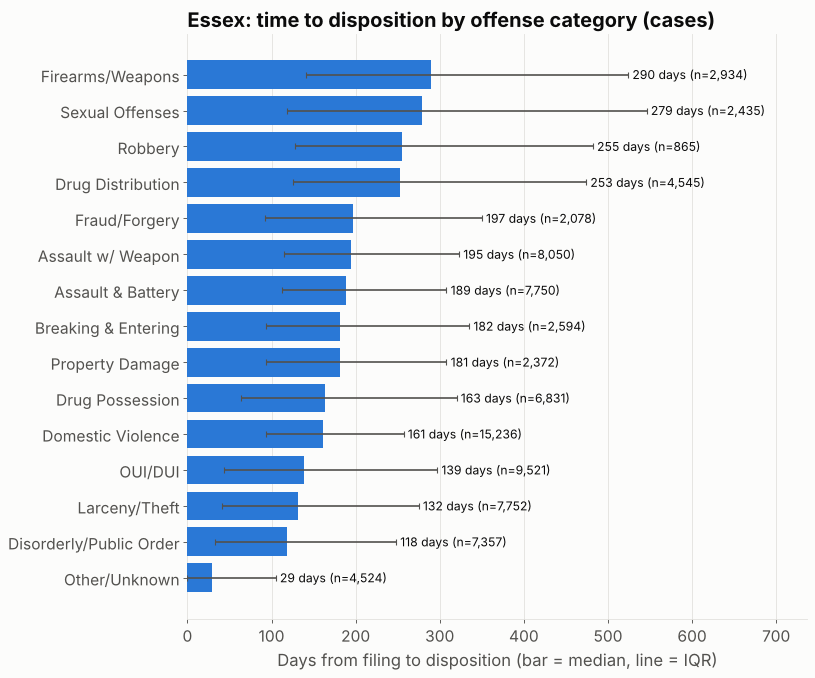

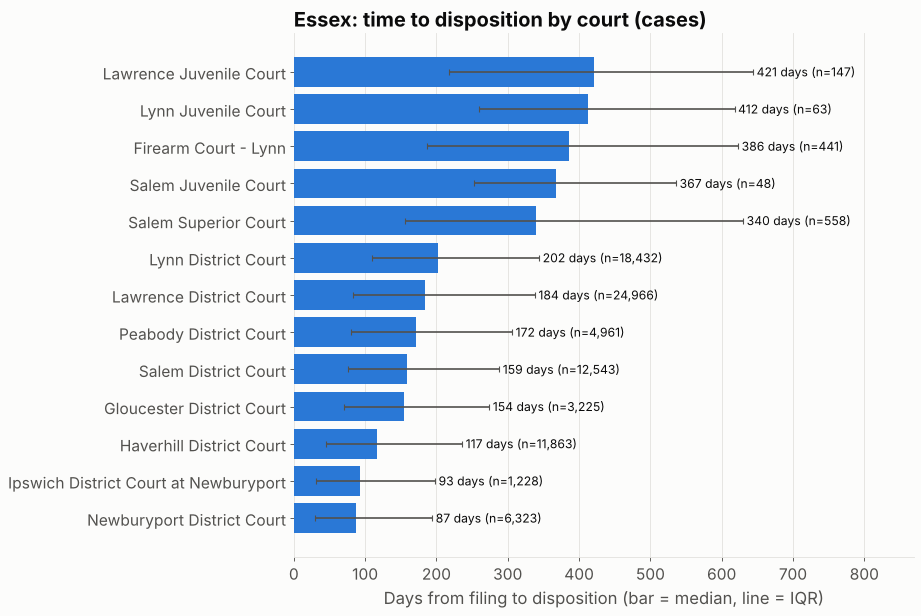

,cases,median_days,q1,q3
court,,,,
Lawrence Juvenile Court,147,421.0,218.0,644.0
Lynn Juvenile Court,63,412.0,259.0,618.0
Firearm Court - Lynn,441,386.0,187.0,623.0
Salem Juvenile Court,48,367.0,252.0,536.0
Salem Superior Court,558,340.0,156.0,630.0
Lynn District Court,18432,202.0,110.0,344.0
Lawrence District Court,24966,184.0,83.0,338.0
Peabody District Court,4961,172.0,80.0,306.0
Salem District Court,12543,159.0,76.0,288.0


In [13]:
t = cases.copy()
t["days"] = (t["disposition_date"] - t["filing_date"]).dt.days
n_negative = (t["days"] < 0).sum()
t = t[t["days"] >= 0]
print(f"{len(t):,} cases used; {n_negative:,} negative intervals excluded")

def iqr_table(group):
    g = t.groupby(group)["days"]
    out = pd.DataFrame({"cases": g.size(), "median_days": g.median(),
                        "q1": g.quantile(0.25), "q3": g.quantile(0.75)})
    return out[out["cases"] >= MIN_CELL].sort_values("median_days", ascending=False).round(0)

by_offense = iqr_table("offense_category")
by_court = iqr_table("court")
print(f"Overall median: {t['days'].median():.0f} days (IQR {t['days'].quantile(.25):.0f}-{t['days'].quantile(.75):.0f})")
print(f"Resolved on the filing day: {(t['days'] == 0).mean():.0%} of cases")

def iqr_chart(table, what, path):
    top = table.head(15).iloc[::-1]
    y = np.arange(len(top))
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(top) + 2))
    ax.barh(y, top["median_days"], color=OUTCOME_COLORS["Trial Conviction"])
    ax.errorbar(top["median_days"], y, xerr=[top["median_days"] - top["q1"], top["q3"] - top["median_days"]],
                fmt="none", ecolor=TEXT_SECONDARY, capsize=3)
    ax.set_yticks(y, top.index)
    for yi, (m, q3, n) in zip(y, zip(top["median_days"], top["q3"], top["cases"])):
        ax.text(q3 + 5, yi, f"{m:.0f} days (n={int(n):,})", va="center", fontsize=11)
    ax.set_xlim(0, top["q3"].max() * 1.35)
    ax.set_xlabel("Days from filing to disposition (bar = median, line = IQR)")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: time to disposition by {what} (cases)")
    save_fig(fig, path)
    plt.show()

iqr_chart(by_offense, "offense category", f"{FIG_DIR}/q6_time_by_offense.png")
iqr_chart(by_court, "court", f"{FIG_DIR}/q6_time_by_court.png")
display(by_court)

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case
- **Filters:** 105 negative intervals excluded; categories with fewer than 30 cases hidden
- **Result:** median 165 days (IQR 72-307); 7% resolved on the arraignment day. Juvenile, firearm and Superior courts take the longest.

## 7. Disparities by Race and Sex
**Question:** Do dismissal and incarceration rates differ by race/ethnicity and sex?
**Metric:** rate per group, plus rate ratios vs. White and vs. Male. Unknown race is kept as its own group. Groups under 30 cases are suppressed.

In [14]:
REF = {"race": "White", "sex": "Male"}

def disparity(df, group, flag, label):
    g = df.groupby(group)[flag].agg(["size", "mean"]).rename(columns={"size": "cases", "mean": "rate"})
    g = g[g["cases"] >= MIN_CELL]
    ref = REF[group]
    g["rate_pct"] = (g["rate"] * 100).round(1)
    g["ratio_vs_ref"] = (g["rate"] / g.loc[ref, "rate"]).round(2) if ref in g.index else np.nan
    return g.drop(columns="rate").assign(metric=label, group_var=group)

cases["dismissed"] = cases["outcome"] == "Dismissal"
results = []
for group in ["race", "sex"]:
    if group in INSUFFICIENT:
        print(f"{group}: insufficient data"); continue
    results.append(disparity(cases, group, "dismissed", "dismissal rate"))
    if "case_sent" in globals():
        inc = case_sent.join(cases.set_index("case_key")[[group]], how="inner")
        inc = inc[inc["sentence"] != "Unknown"]          # rate among convictions with a known sentence
        inc["incarcerated"] = inc["sentence"] == "Incarceration"
        results.append(disparity(inc, group, "incarcerated", "incarceration rate (convicted cases)"))
disp = pd.concat(results) if results else pd.DataFrame()
disp

,cases,rate_pct,ratio_vs_ref,metric,group_var
Asian,593,37.4,1.02,dismissal rate,race
Black,7404,48.0,1.31,dismissal rate,race
Hispanic,15258,47.7,1.30,dismissal rate,race
Other,217,42.4,1.16,dismissal rate,race
Unknown,20437,45.8,1.25,dismissal rate,race
White,41040,36.6,1.00,dismissal rate,race
Asian,117,60.7,1.23,incarceration rate (convicted cases),race
Black,1903,55.5,1.12,incarceration rate (convicted cases),race
Hispanic,4192,58.6,1.19,incarceration rate (convicted cases),race
Other,54,51.9,1.05,incarceration rate (convicted cases),race


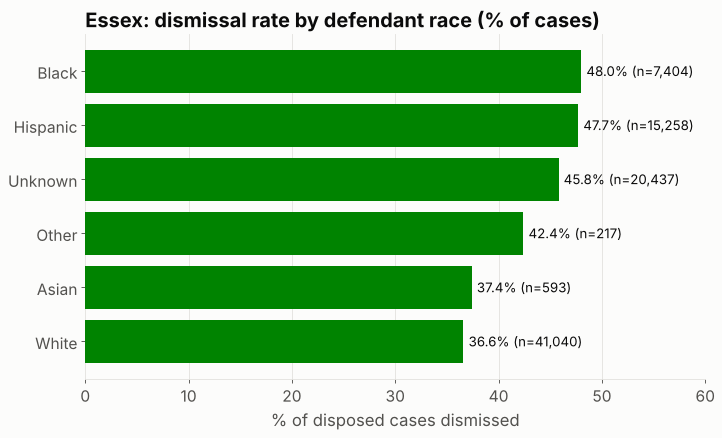

In [15]:
# Dismissal rate by race (chart)
if "race" not in INSUFFICIENT:
    r = disp[(disp["metric"] == "dismissal rate") & (disp["group_var"] == "race")].sort_values("rate_pct")
    y = np.arange(len(r))
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(r) + 2))
    ax.barh(y, r["rate_pct"], color=OUTCOME_COLORS["Dismissal"])
    ax.set_yticks(y, r.index)
    for yi, (v, n) in zip(y, zip(r["rate_pct"], r["cases"])):
        ax.text(v + 0.5, yi, f"{v:.1f}% (n={n:,})", va="center", fontsize=12)
    ax.set_xlim(0, r["rate_pct"].max() * 1.25)
    ax.set_xlabel("% of disposed cases dismissed")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{COUNTY.title()}: dismissal rate by defendant race (% of cases)")
    save_fig(fig, f"{FIG_DIR}/q7_dismissal_by_race.png")
    plt.show()

**How this was calculated**
- **Unit:** disposed cases (dismissal); convicted cases with a known sentence (incarceration)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Race labels:** W White, B Black, H Hispanic, A Asian, M / N / P / PI Other; U, 0 and blank Unknown
- **Filters:** groups under 30 cases suppressed; Unknown kept as its own group
- **Result:** dismissal rate White 36.6%, Black 48.0%, Hispanic 47.7%, Unknown 45.8%. Incarceration rates use the derived sentence (insufficient data, see Q4).

**Note:** Declination (cases the prosecutor declined to file) is not measurable in this extract.

## 8. Disparities with Controls
**Question:** Do racial gaps remain within the same offense category and prior-record level?
**Metric:** dismissal rate by race within offense category × prior-record cells. Cells under 30 cases are suppressed.

**Prior record:** number of earlier cases for the same defendant filed in the **3 years** before this case (same lookback in every county), bucketed 0 / 1-2 / 3+.

In [16]:
LOOKBACK_YEARS = 3
PERSON_ID_LINKS_CASES = True   # Id Prsn Mstr is a person ID shared across cases

if not PERSON_ID_LINKS_CASES:
    prior = pd.Series(dtype=str)
    print("No person ID that links a defendant across cases: prior record not measurable, insufficient data")
elif "race" in INSUFFICIENT:
    prior = pd.Series(dtype=str)
    print("Race: insufficient data")
else:
    # All filed cases (any year) so cases early in the window still see prior history.
    # Same rule as the other counties (county_charts.prior_record_3yr): cases filed in the 3 years before.
    hist = filed.groupby("case_key").agg(person=("defendant_id", "first"), filing_date=("filing_date", "min"))
    prior = cc.prior_record_3yr(hist, LOOKBACK_YEARS)

    c = cases.assign(prior_record=cases["case_key"].map(prior))
    c = c[c["prior_record"].isin(["0", "1-2", "3+"])]
    cell = (c.groupby(["offense_category", "prior_record", "race"])["dismissed"]
              .agg(cases="size", rate="mean").reset_index())
    cell = cell[cell["cases"] >= MIN_CELL]
    cell["rate_pct"] = (cell["rate"] * 100).round(1)

    wide = cell.pivot_table(index=["offense_category", "prior_record"], columns="race", values="rate_pct")
    if REF["race"] in wide.columns:
        for col in [c_ for c_ in wide.columns if c_ != REF["race"]]:
            wide[f"{col} ratio"] = (wide[col] / wide[REF["race"]]).round(2)
    print(f"Cases with a known prior record: {len(c):,}")
    display(wide)

Cases with a known prior record: 84,949


race                                  Asian  ...  Unknown ratio
offense_category        prior_record         ...               
Assault & Battery       0               NaN  ...           1.23
                        1-2             NaN  ...           1.14
                        3+              NaN  ...           0.84
Assault w/ Weapon       0              52.6  ...           1.19
                        1-2             NaN  ...           1.19
                        3+              NaN  ...           1.46
Breaking & Entering     0               NaN  ...           1.44
                        1-2             NaN  ...           1.24
                        3+              NaN  ...           1.66
Disorderly/Public Order 0              43.8  ...           1.20
                        1-2             NaN  ...           1.17
                        3+              NaN  ...           1.59
Domestic Violence       0              59.2  ...           1.18
                        1-2             NaN  ...           1.17
                        3+              NaN  ...           1.02
Drug Distribution       0               NaN  ...           1.29
                        1-2             NaN  ...           1.24
                        3+              NaN  ...           1.11
Drug Possession         0               NaN  ...           1.23
                        1-2             NaN  ...           1.05
                        3+              NaN  ...           0.69
Firearms/Weapons        0               NaN  ...           1.50
                        1-2             NaN  ...           1.29
                        3+              NaN  ...            NaN
Fraud/Forgery           0               NaN  ...           1.21
                        1-2             NaN  ...           1.25
                        3+              NaN  ...            NaN
Larceny/Theft           0               NaN  ...           1.18
                        1-2             NaN  ...           1.03
                        3+              NaN  ...           1.11
OUI/DUI                 0               4.0  ...           1.11
                        1-2             NaN  ...           1.47
                        3+              NaN  ...            NaN
Other/Unknown           0               NaN  ...           0.97
                        1-2             NaN  ...           0.93
                        3+              NaN  ...            NaN
Property Damage         0               NaN  ...           1.26
                        1-2             NaN  ...           1.26
                        3+              NaN  ...            NaN
Robbery                 0               NaN  ...           1.08
                        1-2             NaN  ...           1.21
                        3+              NaN  ...            NaN
Sexual Offenses         0               NaN  ...           1.23
                        1-2             NaN  ...           1.63
                        3+              NaN  ...            NaN

[45 rows x 9 columns]

**How this was calculated**
- **Unit:** disposed cases
- **Prior record:** earlier cases for the same person (`Id Prsn Mstr`) filed within 3 years before this case (`county_charts.prior_record_3yr`)
- **Cells:** offense category × prior record × race; cells under 30 cases suppressed
- **Ratio:** group dismissal rate / White dismissal rate within the same cell

**Limitation:** Prior record only counts cases in this county's extract (from 2017), not statewide history, so cases early in the window undercount prior record.

## Standard Figure Set
The shared figures used for every county (`county_charts.standard_figures`), drawn from the case table above so all counties are measured and labeled the same way. Q8 is shown as the heatmap of dismissal-rate ratios within offense × prior-record cells.

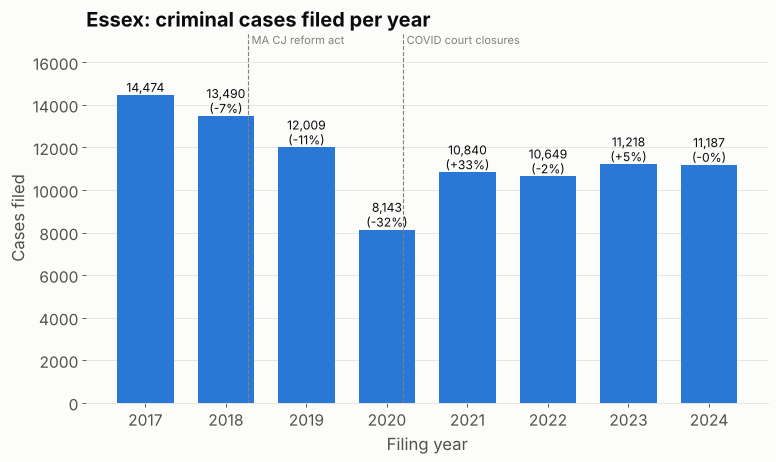

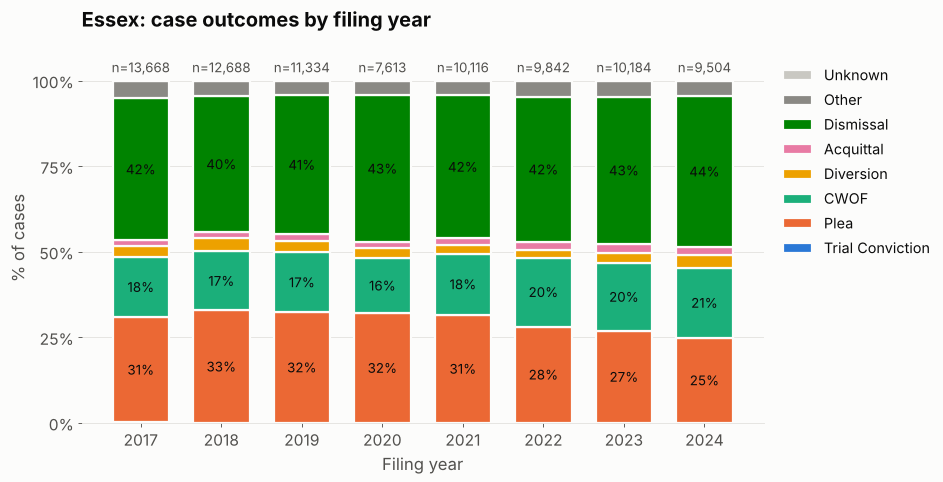

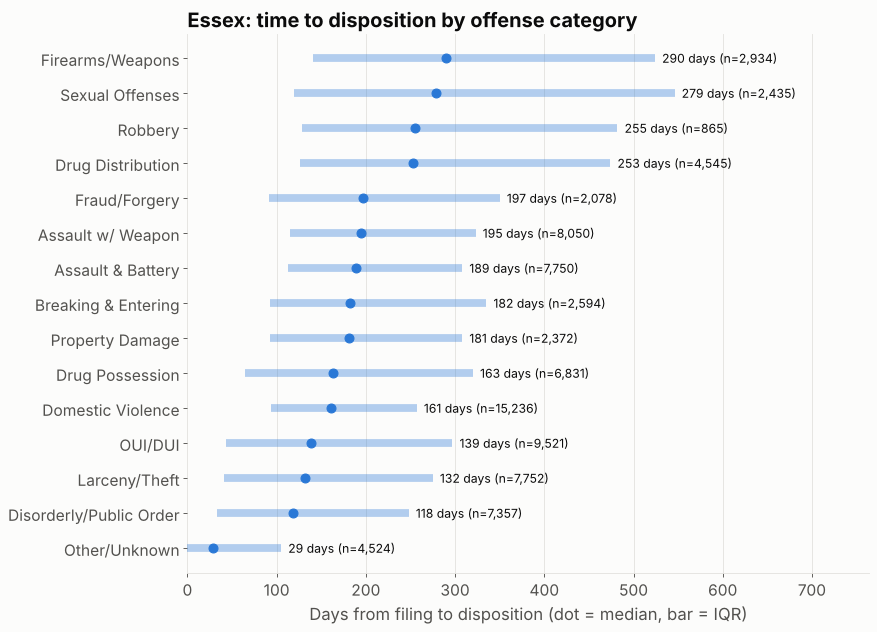

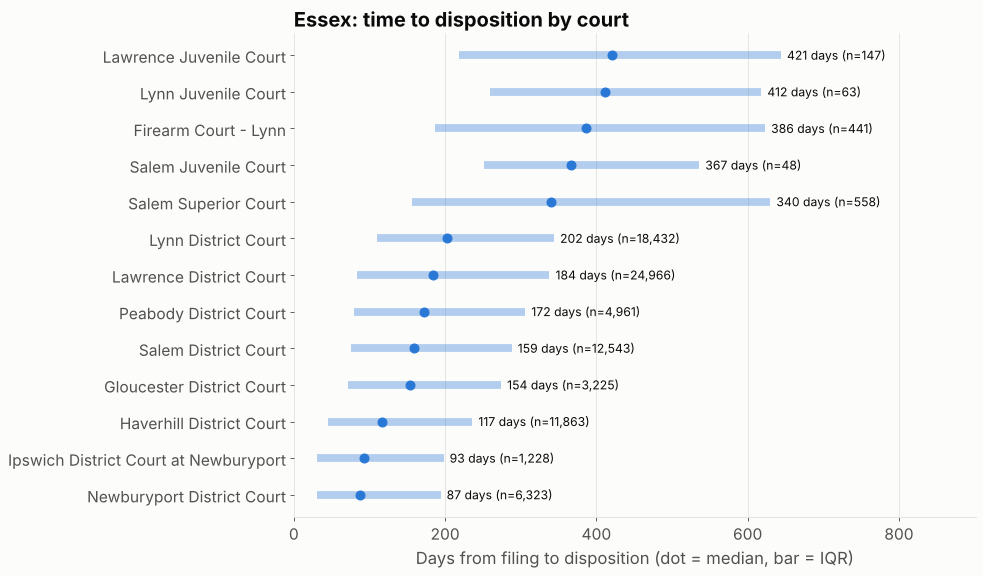

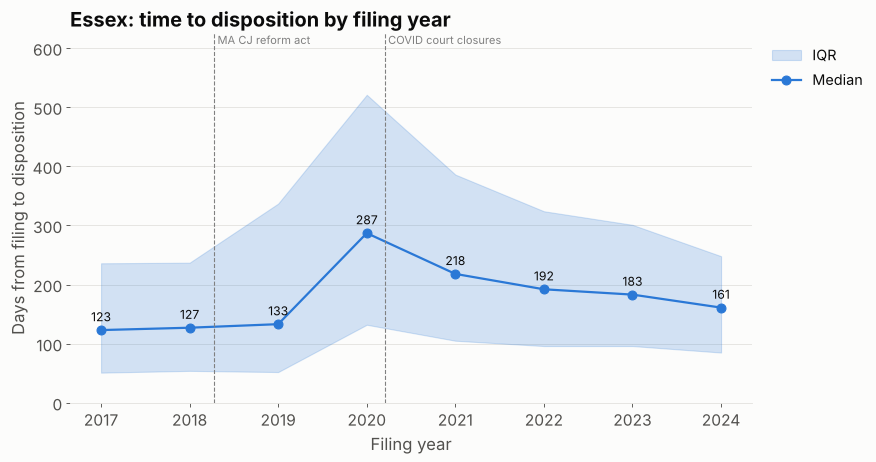

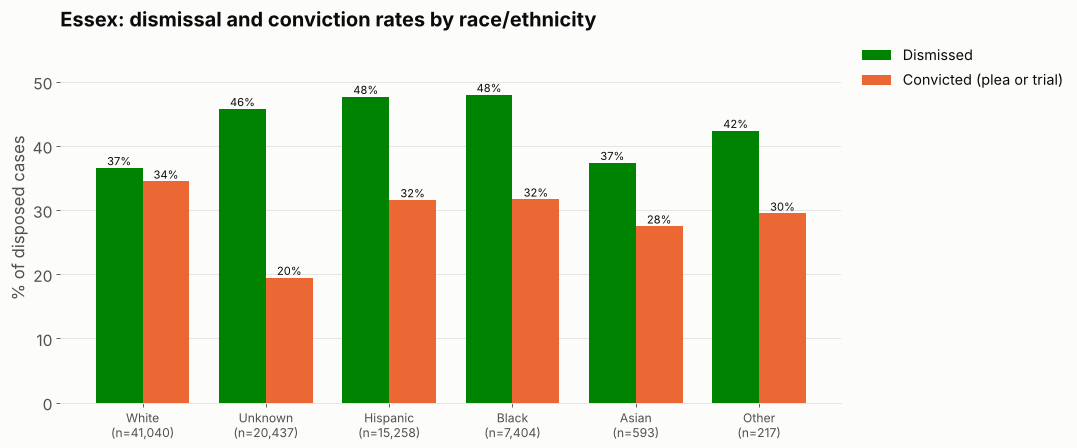

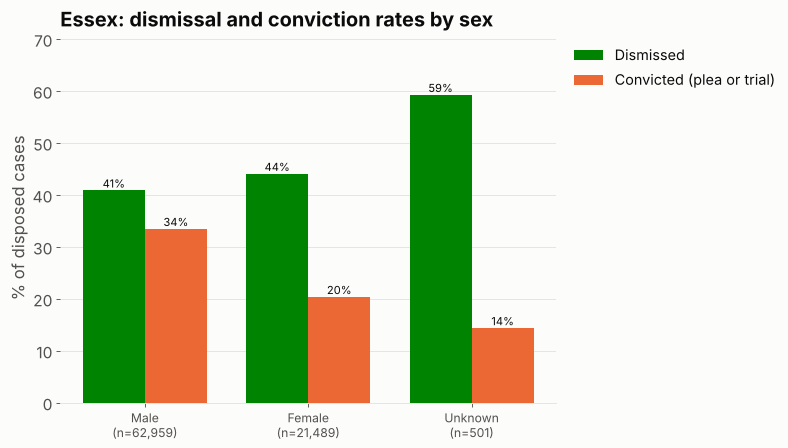

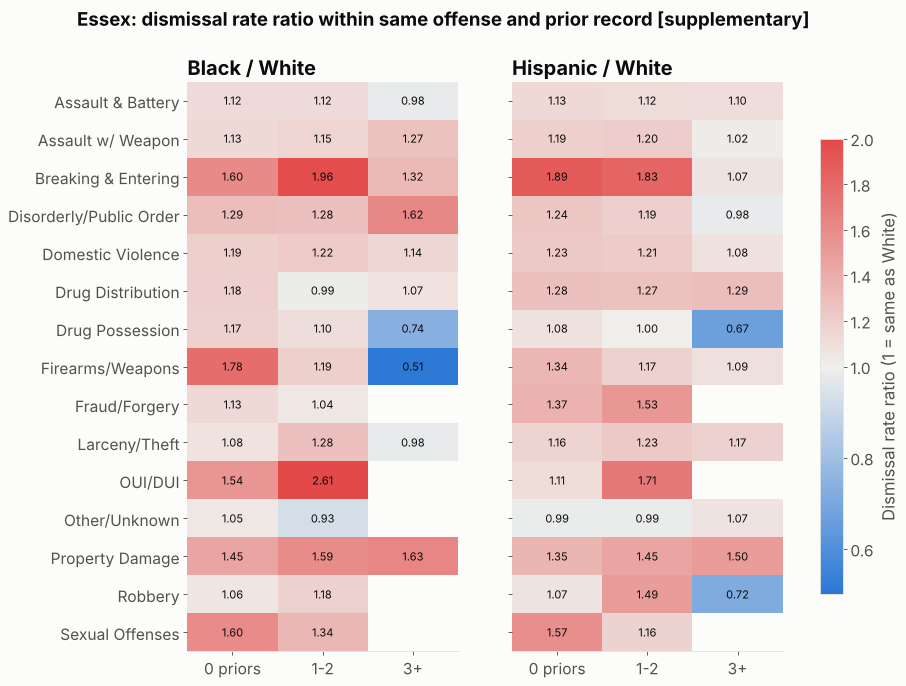

Q8 cases with known prior record: 84,949


In [17]:
std = pd.DataFrame({
    "case_key": cases["case_key"],
    "year": cases["filing_year"].astype(int),
    "outcome": cases["outcome"],
    "offense": cases["offense_category"],
    "court": cases["court"],
    "race": cases["race"],
    "sex": cases["sex"],
    "days": (cases["disposition_date"] - cases["filing_date"]).dt.days,
    "prior_record": cases["case_key"].map(prior).fillna("Unknown"),
})
std.loc[std["days"] < 0, "days"] = np.nan
vol_series = vol["cases"]

tables = cc.standard_figures(std, vol_series, COUNTY, FIG_DIR, prefix="std_", q8_supplementary=True)

**Notes:** figures are saved with a `std_` prefix in `figures/essex/` (300 DPI). The Q8 heatmap is marked supplementary.

## Questions for the Client
- Does "Guilty" (GLT and its variants) come from pleas, trials, or both? Is there a field that says which?
- Race codes M, N, P, PI, and 0: what do they stand for?
- Is there a sentence-type field, or is the jail-time block the only sentencing record? What does unit "P" mean in the jail fields?
- Can a felony / misdemeanor flag be added?
- Can declined referrals be provided?